# OTFS: модуляция в координатах задержка–доплер

OFDM (`lte_sim`) превращает многолучевый канал в набор плоских поднесущих, но только пока канал не меняется за символ. На поезде, в самолёте или на спутнике доплер ломает ортогональность поднесущих (ICI), а оценки канала устаревают быстрее, чем их обновляют пилоты. Канал $H(t,f)$ на частотно-временной (TF) сетке меняется **везде**.

При этом физических лучей мало, и каждый из них — это **неподвижная** точка: задержка $\tau_i$ (длина пути) и доплер $\nu_i$ (скорость и угол). Канал как функция рассеяния
$$r(t)=\sum_i h_i\,e^{j2\pi\nu_i t}\,s(t-\tau_i)\qquad\Longleftrightarrow\qquad h(\tau,\nu)=\sum_i h_i\,\delta(\tau-\tau_i)\,\delta(\nu-\nu_i)$$
разрежен и постоянен на интервалах в десятки миллисекунд. **OTFS** (Hadani et al., 2017) кладёт символы прямо на сетку **задержка–доплер** (DD) $M\times N$ с шагом $\Delta\tau=1/(M\Delta f)$, $\Delta\nu=1/(NT)$. Переход в TF — **ISFFT**:
$$X[m,n]=\frac1{\sqrt{MN}}\sum_{k=0}^{N-1}\sum_{l=0}^{M-1}x[l,k]\,e^{\,j2\pi\left(\frac{nk}{N}-\frac{ml}{M}\right)},$$
а дальше обычный OFDM-модулятор. Приёмник делает OFDM-демодуляцию и SFFT обратно. В DD канал — это **двумерная циклическая свёртка**:
$$y[l,k]\approx\sum_i h_i\,x\big[(l-l_i)_M,\,(k-k_i)_N\big]\,e^{j\phi_i(l,k)}.$$
Каждый DD-символ размазан по **всему** кадру $M\times N$ в TF, поэтому видит все замирания сразу и получает всё разнесение по времени и частоте. Канал же — несколько чисел, которые не меняются за кадр.

В этом и следующих ноутбуках — семейство «волн для каналов с доплером»: OTFS (здесь), **Zak-OTFS** (OTFS 2.0, решётка Зака и дробный доплер), **AFDM** и **OCDM** (чирпы, родственники LoRa) и **OTSM/ODDM** (одна несущая в DD).

1. Канал в TF и DD · 2. Один DD-символ: импульсы во времени и гребёнка по частоте · 3. Вход–выход в DD, дробный доплер · 4. OFDM против OTFS на 500 км/ч · 5. Встроенный пилот и оценка канала · 6. Детектор передачи сообщений · 7. Пик-фактор

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
M, N = 64, 16          # бинов задержки (поднесущих) × бинов доплера (OFDM-символов)
DF = 15e3              # разнос поднесущих, Гц
L_CP = 8               # CP, отсчётов: у OTFS один на кадр, у OFDM — на каждый символ
FC_GHZ = 4.0
SPEED_KMH = 500        # высокоскоростной поезд
P_PATHS = 5            # лучей; задержки 0…P−1 отсчётов, мощность спадает экспоненциально
FRAMES = 40            # реализаций канала на точку BER

rng = np.random.default_rng(SEED)

## Примитивы: OTFS и OFDM модуляторы, канал с лучами, эффективная матрица, LMMSE

In [2]:
MN = M * N
FS = M * DF; T = 1 / DF                       # отсчёт 1/(MΔf), символ T = 1/Δf
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
K_MAX = NU_MAX * N * T                        # максимальный доплер в бинах 1/(NT)
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)   # индекс = 2·b_Q + b_I (Грей)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, rng):
    b = rng.integers(0, 2, (B, MN, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

# ---------- модуляторы: вектор длины MN, индекс l·N + k (OTFS) или m·N + n (OFDM) ----------
def otfs_mod(x):
    """x[l,k] (…, M·N) → кадр: IDFT по доплеру даёт N блоков по M отсчётов, блок n = столбец n; один CP на весь кадр."""
    X = x.reshape(x.shape[:-1] + (M, N))
    s = (np.fft.ifft(X, axis=-1) * np.sqrt(N)).swapaxes(-1, -2).reshape(x.shape[:-1] + (MN,))
    return np.concatenate([s[..., -L_CP:], s], -1)

def otfs_demod(r):
    Y = r[..., L_CP:L_CP + MN].reshape(r.shape[:-1] + (N, M)).swapaxes(-1, -2)
    return (np.fft.fft(Y, axis=-1) / np.sqrt(N)).reshape(r.shape[:-1] + (MN,))

def isfft(x):
    """ISFFT: x[l,k] → X[m,n] = (1/√MN) Σ x[l,k]·e^{j2π(nk/N − ml/M)}"""
    X = x.reshape(x.shape[:-1] + (M, N))
    return np.fft.ifft(np.fft.fft(X, axis=-2), axis=-1) * np.sqrt(N / M)

def ofdm_mod(X, cp=L_CP):
    """X[m,n] (…, M·N) → N символов OFDM, у каждого свой CP"""
    G = X.reshape(X.shape[:-1] + (M, N))
    s = (np.fft.ifft(G, axis=-2) * np.sqrt(M)).swapaxes(-1, -2)     # (…, N, M)
    return np.concatenate([s[..., -cp:], s], -1).reshape(X.shape[:-1] + (N * (M + cp),))

def ofdm_demod(r, cp=L_CP):
    s = r.reshape(r.shape[:-1] + (N, M + cp))[..., cp:]
    return (np.fft.fft(s, axis=-1) / np.sqrt(M)).swapaxes(-1, -2).reshape(r.shape[:-1] + (MN,))

# ---------- двукратно-рассеивающий канал: лучи (h_i, задержка l_i, доплер ν_i) ----------
def draw_paths(rng, integer=False):
    """P лучей на задержках 0…P−1, доплер ν_max·cos θ (Джейкс), integer=True — доплер округлён до бина 1/(NT)."""
    p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
    nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi, P_PATHS))
    if integer:
        nu = np.round(nu * N * T) / (N * T)
    return [(np.sqrt(pi) * crandn((), rng), l, v) for l, (pi, v) in enumerate(zip(p, nu))]

def channel(s, paths):
    """r[n] = Σ_i h_i·e^{j2πν_i n/f_s}·s[n − l_i]"""
    n = np.arange(s.shape[-1]); r = np.zeros(s.shape, complex)
    for h, l, nu in paths:
        r[..., l:] += h * np.exp(2j * np.pi * nu * n[l:] / FS) * s[..., :s.shape[-1] - l]
    return r

def eff_matrix(paths, mod=otfs_mod, demod=otfs_demod):
    """Эффективная матрица MN×MN «символы → выход демодулятора»: прогоняем через цепочку все базисные векторы."""
    return demod(channel(mod(np.eye(MN, dtype=complex)), paths)).T

def lmmse(H, y, n0):
    """x̂ = (HᴴH + N0·I)⁻¹Hᴴy для пачки y (B, MN)"""
    return np.linalg.solve(H.conj().T @ H + n0 * np.eye(H.shape[1]), H.conj().T @ y.T).T

def tf_channel(paths):
    """H(t, f) на сетке: середины символов × поднесущие"""
    t = (np.arange(N) * (M + L_CP) + L_CP + M / 2) / FS; f = np.arange(M) * DF
    return sum(h * np.exp(2j * np.pi * nu * t)[None, :] * np.exp(-2j * np.pi * f * l / FS)[:, None] for h, l, nu in paths)

# самопроверки
_b, _x = qpsk_bits(3, rng)
assert np.allclose(otfs_demod(otfs_mod(_x)), _x) and np.allclose(ofdm_demod(ofdm_mod(_x)), _x)
_s_isfft = (np.fft.ifft(isfft(_x), axis=-2) * np.sqrt(M)).swapaxes(-1, -2).reshape(3, MN)    # ISFFT → OFDM без CP
assert np.allclose(_s_isfft, otfs_mod(_x)[:, L_CP:]), "ISFFT + Heisenberg ≠ IDFT по доплеру"
print(f"Сетка {M}×{N}: Δτ = 1/(MΔf) = {1e6/FS:.2f} мкс, Δν = 1/(NT) = {1/(N*T):.1f} Гц; кадр {MN/FS*1e3:.3f} мс + CP {L_CP} отсч.")
print(f"{SPEED_KMH} км/ч на {FC_GHZ} ГГц: ν_max = {NU_MAX:.0f} Гц = {K_MAX:.2f} бина доплера = {NU_MAX/DF:.3f}·Δf")
print(f"Накладные расходы CP: OTFS {L_CP/(MN+L_CP):.1%}, OFDM {L_CP/(M+L_CP):.1%}")

Сетка 64×16: Δτ = 1/(MΔf) = 1.04 мкс, Δν = 1/(NT) = 937.5 Гц; кадр 1.067 мс + CP 8 отсч.
500 км/ч на 4.0 ГГц: ν_max = 1852 Гц = 1.98 бина доплера = 0.123·Δf
Накладные расходы CP: OTFS 0.8%, OFDM 11.1%


## 1. Один и тот же канал в TF и в DD
Модель: $P$ лучей на задержках $0\dots P-1$ отсчётов с экспоненциальным профилем, доплер каждого $\nu_i=\nu_\max\cos\theta_i$ (углы прихода равномерны, как у Джейкса). На 500 км/ч и 4 ГГц $\nu_\max\approx1.85$ кГц, это ~2 бина доплера $1/(NT)$.

Слева — $|H(t,f)|$ за один кадр 1.2 мс: провалы бегут и по частоте (задержки), и по времени (доплер), а время когерентности $\approx0.42/\nu_\max$ в ~5 раз короче кадра. Посередине — тот же канал в DD: пять точек, которые за кадр не сдвигаются. Справа — что видит одна поднесущая OFDM: её коэффициент за кадр несколько раз проходит через провал.

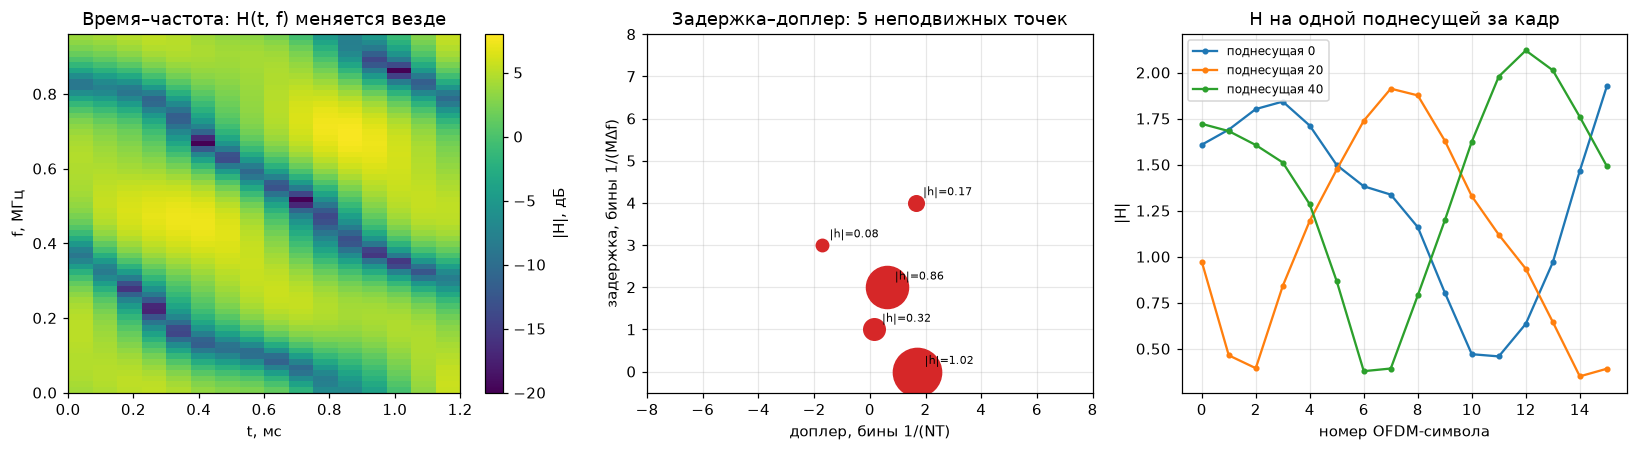

Время когерентности 0.423/ν_max = 0.23 мс при кадре 1.20 мс: за кадр канал в TF «перемешивается» ~5 раз
В TF: 1024 комплексных чисел, меняющихся во времени; в DD: 5 лучей × (h, τ, ν) = 15 параметров, постоянных за кадр


In [3]:
pth = draw_paths(np.random.default_rng(3))
Htf = tf_channel(pth)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
im = ax[0].imshow(20 * np.log10(np.abs(Htf)), origin="lower", aspect="auto", cmap="viridis",
                  extent=[0, N * (M + L_CP) / FS * 1e3, 0, M * DF / 1e6], vmin=-20, vmax=8)
plt.colorbar(im, ax=ax[0], label="|H|, дБ"); ax[0].grid(False)
ax[0].set_xlabel("t, мс"); ax[0].set_ylabel("f, МГц"); ax[0].set_title("Время–частота: H(t, f) меняется везде")
for h, l, nu in pth:
    ax[1].plot(nu / (1 / (N * T)), l, "o", ms=6 + 25 * abs(h), color="C3")
    ax[1].annotate(f"|h|={abs(h):.2f}", (nu / (1 / (N * T)), l), xytext=(5, 5), textcoords="offset points", fontsize=7)
ax[1].set_xlim(-N / 2, N / 2); ax[1].set_ylim(-0.5, M / 8)
ax[1].set_xticks(np.arange(-N // 2, N // 2 + 1, 2)); ax[1].set_yticks(range(M // 8 + 1))
ax[1].set_xlabel("доплер, бины 1/(NT)"); ax[1].set_ylabel("задержка, бины 1/(MΔf)")
ax[1].set_title(f"Задержка–доплер: {P_PATHS} неподвижных точек")
for m in (0, 20, 40):
    ax[2].plot(np.arange(N), np.abs(Htf[m]), "o-", ms=3, label=f"поднесущая {m}")
ax[2].set_xlabel("номер OFDM-символа"); ax[2].set_ylabel("|H|"); ax[2].legend(fontsize=8)
ax[2].set_title("H на одной поднесущей за кадр")
plt.tight_layout(); plt.show()
tc = 0.423 / NU_MAX
print(f"Время когерентности 0.423/ν_max = {tc*1e3:.2f} мс при кадре {N*(M+L_CP)/FS*1e3:.2f} мс: за кадр канал в TF «перемешивается» ~{N*(M+L_CP)/FS/tc:.0f} раз")
print(f"В TF: {MN} комплексных чисел, меняющихся во времени; в DD: {P_PATHS} лучей × (h, τ, ν) = {3*P_PATHS} параметров, постоянных за кадр")

## 2. Один DD-символ: N импульсов во времени
С прямоугольным импульсом ISFFT + OFDM без CP сводятся к одному IDFT по оси доплера:
$$s[l+nM]=\frac1{\sqrt N}\sum_{k}x[l,k]\,e^{\,j2\pi nk/N},\qquad n=0\dots N-1.$$
Символ $(l_0,k_0)$ — это $N$ импульсов в позициях $l_0+nM$, у которых фаза вращается на $2\pi k_0/N$ от импульса к импульсу. Задержка — это **где** внутри блока, доплер — **как быстро вращается** фаза. В TF (слева) тот же символ — двумерная экспонента постоянной амплитуды $1/\sqrt{MN}$ на всей сетке, в спектре (справа) — гребёнка на всю полосу. Отсюда разнесение: символ присутствует на всех частотах и во все моменты кадра.

CP один на весь кадр: свёртка с каналом циклическая по всему кадру, а не по символам. Накладные расходы 0.8 % вместо 11 % у OFDM с тем же CP.

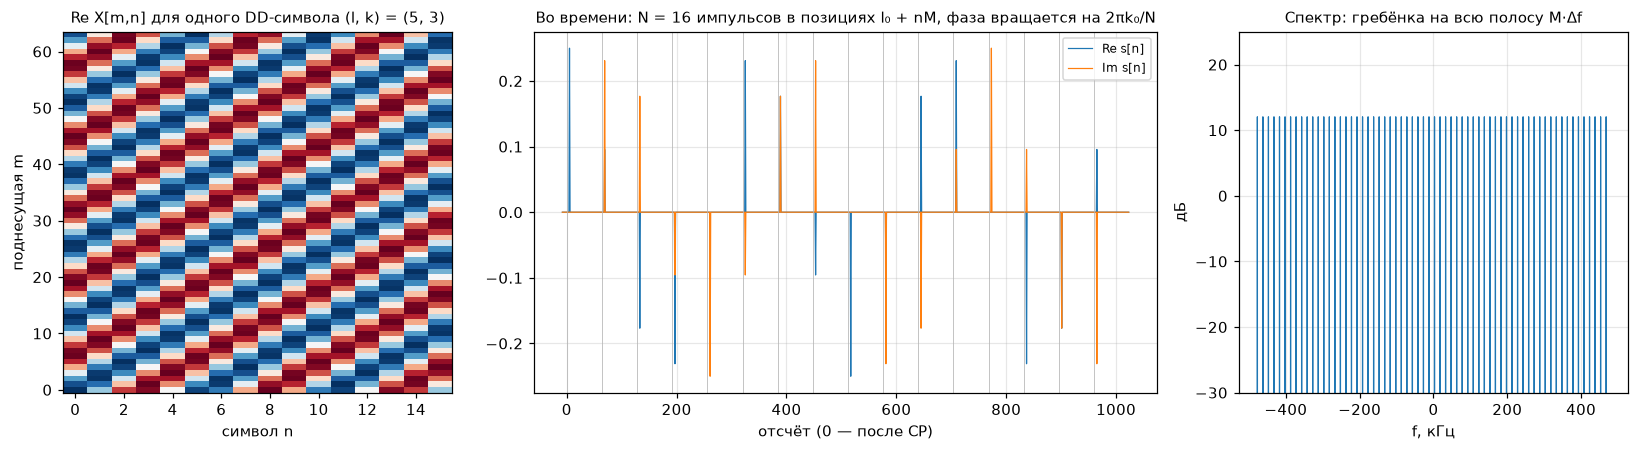

Набег фазы импульсов: [67.5 67.5 67.5 67.5 67.5]… °, теория 360·k₀/N = 67.5°
|X[m,n]| = 0.0312…0.0313 = 1/√MN = 0.0312: каждый DD-символ занимает весь TF-кадр


In [4]:
l0, k0 = 5, 3
x = np.zeros(MN, complex); x[l0 * N + k0] = 1
X = isfft(x).reshape(M, N); s = otfs_mod(x)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.6, 1]})
ax[0].imshow(X.real, origin="lower", aspect="auto", cmap="RdBu", extent=[-0.5, N - 0.5, -0.5, M - 0.5])
ax[0].set_xlabel("символ n"); ax[0].set_ylabel("поднесущая m"); ax[0].grid(False)
ax[0].set_title(f"Re X[m,n] для одного DD-символа (l, k) = ({l0}, {k0})", fontsize=10)
n = np.arange(len(s)) - L_CP
ax[1].plot(n, s.real, "C0", lw=0.8, label="Re s[n]"); ax[1].plot(n, s.imag, "C1", lw=0.8, label="Im s[n]")
for b in range(N):
    ax[1].axvline(b * M, color="0.7", lw=0.5)
ax[1].set_xlabel("отсчёт (0 — после CP)"); ax[1].legend(fontsize=8, loc="upper right")
ax[1].set_title(f"Во времени: N = {N} импульсов в позициях l₀ + nM, фаза вращается на 2πk₀/N", fontsize=10)
S = np.fft.fftshift(np.fft.fft(s[L_CP:])); f = np.fft.fftshift(np.fft.fftfreq(MN, 1 / FS))
ax[2].plot(f / 1e3, 20 * np.log10(np.abs(S) + 1e-9), lw=0.8)
ax[2].set_ylim(-30, 25); ax[2].set_xlabel("f, кГц"); ax[2].set_ylabel("дБ")
ax[2].set_title("Спектр: гребёнка на всю полосу M·Δf", fontsize=10)
plt.tight_layout(); plt.show()
ph = np.angle(s[L_CP + l0 + M * np.arange(N)] * np.conj(s[L_CP + l0]))
print(f"Набег фазы импульсов: {np.degrees(np.diff(np.unwrap(ph))).round(1)[:5]}… °, теория 360·k₀/N = {360*k0/N:.1f}°")
print(f"|X[m,n]| = {np.abs(X).min():.4f}…{np.abs(X).max():.4f} = 1/√MN = {1/np.sqrt(MN):.4f}: каждый DD-символ занимает весь TF-кадр")

## 3. Вход–выход в DD: целый и дробный доплер
Отправим один пилот в $(l_p,k_p)$. Луч $(h_i,l_i,\nu_i)$ сдвигает его на $l_i$ по задержке и на $k_i=\nu_iNT$ по доплеру. Если $k_i$ целое, это ровно одна клетка с $|y|=|h_i|$, и матрица канала в DD — $P$ ненулевых элементов в строке. Её столбцы — циклические сдвиги друг друга (с точностью до фаз), то есть канал **инвариантен к сдвигу**.

Реальный доплер дробный. Фаза $e^{j2\pi\nu t}$ на кадре длиной $NT$ — это не целое число периодов, и по оси доплера отклик размазывается **ядром Дирихле**
$$\Big|\frac{\sin\pi(k-k_i)}{N\sin(\pi(k-k_i)/N)}\Big|.$$
В худшем случае (полбина) вне двух ближайших бинов уходит ~19 % энергии, а строка матрицы перестаёт быть разреженной ($P\cdot N$ элементов). Это главная практическая беда «классической» OTFS. Zak-OTFS (следующий ноутбук) решает её другим выбором импульса.

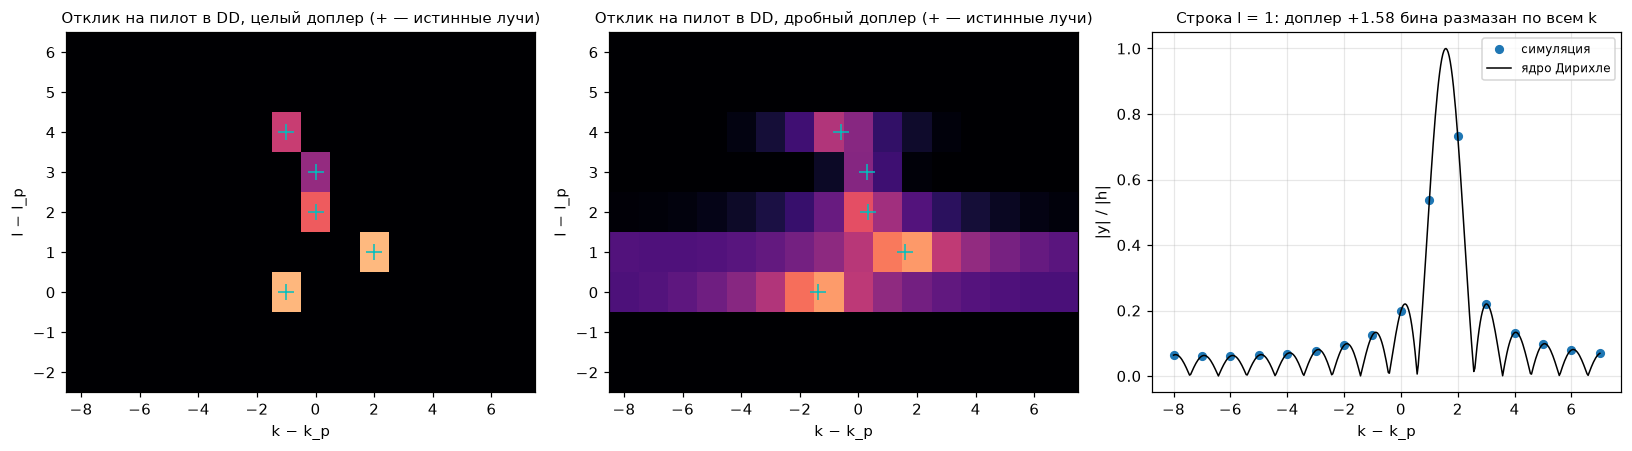

Целый доплер: пик ↔ луч
   l = 0, k = -1: |y| = 0.499, |h| = 0.499
   l = 1, k = +2: |y| = 0.514, |h| = 0.514
   l = 2, k = +0: |y| = 0.204, |h| = 0.204
   l = 3, k = +0: |y| = 0.069, |h| = 0.069
   l = 4, k = -1: |y| = 0.123, |h| = 0.123
Дробный доплер: энергия вне 2 ближайших бинов — 17.7% у луча l = 1 (дробная часть 0.58), 18.7% в худшем случае (0.5 бина)
Сдвиговая инвариантность: |H(·, p₂)| и сдвинутый |H(·, p₁)| отличаются максимум на 1.1e-16 (у OTFS с одним CP — с точностью до фаз)
Ненулевых элементов в строке H_eff: целый доплер 5.0 (= P = 5), дробный 80.0 (= P·N = 80)


In [5]:
def dirichlet(dk):
    """Отклик по доплеру на дробный сдвиг dk: модуль sin(π dk)/(N sin(π dk/N))"""
    dk = np.asarray(dk, float)
    with np.errstate(invalid="ignore", divide="ignore"):
        v = np.abs(np.sin(np.pi * dk) / (N * np.sin(np.pi * dk / N)))
    return np.where(np.abs(np.sin(np.pi * dk / N)) < 1e-12, 1.0, v)

lp, kp = M // 2, N // 2
SEED_S3 = 7   # реализация, где сильнейший луч сидит посередине между бинами доплера
xp = np.zeros(MN, complex); xp[lp * N + kp] = 1
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
res = {}
for a, integer, t in ((ax[0], True, "целый доплер"), (ax[1], False, "дробный доплер")):
    pth = draw_paths(np.random.default_rng(SEED_S3), integer)
    y = otfs_demod(channel(otfs_mod(xp), pth)).reshape(M, N)
    res[integer] = (pth, y)
    a.imshow(20 * np.log10(np.abs(y[lp - 2:lp + P_PATHS + 2]) + 1e-6), origin="lower", aspect="auto", cmap="magma", vmin=-40, vmax=0,
             extent=[-N / 2 - 0.5, N / 2 - 0.5, -2.5, P_PATHS + 1.5])
    for h, l, nu in pth:
        a.plot(nu * N * T, l, "c+", ms=10)
    a.set_xlabel("k − k_p"); a.set_ylabel("l − l_p"); a.set_title(f"Отклик на пилот в DD, {t} (+ — истинные лучи)", fontsize=10)
    a.grid(False)
pth, y = res[False]
hF, lF, nuF = max(pth, key=lambda p: abs(p[0]))
kk = np.arange(N) - kp
ax[2].plot(kk, np.abs(y[lp + lF]) / abs(hF), "C0o", ms=5, label="симуляция")
kg = np.linspace(-N / 2, N / 2 - 1, 400)
ax[2].plot(kg, dirichlet(kg - nuF * N * T), "k-", lw=1, label="ядро Дирихле")
ax[2].set_xlabel("k − k_p"); ax[2].set_ylabel("|y| / |h|"); ax[2].legend(fontsize=8)
ax[2].set_title(f"Строка l = {lF}: доплер {nuF*N*T:+.2f} бина размазан по всем k", fontsize=10)
plt.tight_layout(); plt.show()

pth_i, y_i = res[True]
print("Целый доплер: пик ↔ луч")
for h, l, nu in pth_i:
    k = int(round(nu * N * T))
    print(f"   l = {l}, k = {k:+d}: |y| = {abs(y_i[lp + l, (kp + k) % N]):.3f}, |h| = {abs(h):.3f}")
fr = nuF * N * T - np.floor(nuF * N * T)
out = lambda f_: 1 - np.sum(np.sort(dirichlet(np.arange(N) - N // 2 - f_))[-2:]**2)
print(f"Дробный доплер: энергия вне 2 ближайших бинов — {out(fr):.1%} у луча l = {lF} (дробная часть {fr:.2f}), {out(0.5):.1%} в худшем случае (0.5 бина)")
H = eff_matrix(pth_i)
c1, c2 = H[:, (lp * N + kp)], H[:, ((lp + 7) * N + kp + 3) % MN]
c1s = np.roll(c1.reshape(M, N), (7, 3), (0, 1)).ravel()
print(f"Сдвиговая инвариантность: |H(·, p₂)| и сдвинутый |H(·, p₁)| отличаются максимум на {np.max(np.abs(np.abs(c2) - np.abs(c1s))):.1e} (у OTFS с одним CP — с точностью до фаз)")
print(f"Ненулевых элементов в строке H_eff: целый доплер {np.mean(np.sum(np.abs(H) > 1e-6, 1)):.1f} (= P = {P_PATHS}), дробный {np.mean(np.sum(np.abs(eff_matrix(pth)) > 1e-6, 1)):.1f} (= P·N = {P_PATHS*N})")

## 4. OFDM против OTFS при 500 км/ч
**ICI в OFDM.** Поднесущая с доплером $\nu$ на интервале $T$ перестаёт попадать в нули соседей. Мощность, ушедшая из диагонали матрицы канала, равна
$$P_\text{ICI}=1-\sum_ip_i\,\mathrm{sinc}^2(\nu_iT)\approx\frac{(\pi\nu_\max T)^2}{6}$$
(та же формула, что в разделе 5 `lte_sim`). На 500 км/ч это −16 дБ — потолок SINR для одноотводного эквалайзера.

**BER без кода, QPSK**, канал меняется от кадра к кадру, CSI идеальная:
- **OFDM, один отвод** — деление на диагональ: насыщается на полу ICI;
- **OFDM, полный LMMSE** — та же матрица OFDM, но с учётом ICI. Пол уходит, но наклон остаётся **1 декада на 10 дБ**: каждый символ живёт на одной поднесущей в одном символе, и его замирание — Рэлей;
- **OTFS, LMMSE** — та же энергия, тот же канал, но каждый символ размазан по всему кадру. Наклон ~3 декады на 10 дБ: детектор собирает разнесение по лучам (их 5).

Без всякого кода OTFS выигрывает ~10 дБ при BER $10^{-3}$. С сильным кодом и перемежением по всему кадру OFDM тоже собирает это разнесение (раздел 8 `lte_sim`), и разрыв сокращается до долей–единиц дБ. Строго говоря, у OTFS без поворота фазы асимптотический порядок разнесения равен 1 (Surabhi et al., 2019). Но до BER ~$10^{-5}$ видна именно эта эффективная крутизна.

OFDM, ICI / полезная мощность, дБ: симуляция (точная формула 1 − Σp_i·sinc²(ν_i T))
   30 км/ч: -40.6 (-40.5)  120 км/ч: -28.5 (-28.5)  250 км/ч: -22.2 (-22.1)  500 км/ч: -16.1 (-16.1)  750 км/ч: -12.5 (-12.7)  1000 км/ч: -10.0 (-10.3)  1500 км/ч: -6.2 (-7.1)


40 реализаций канала за 51 с


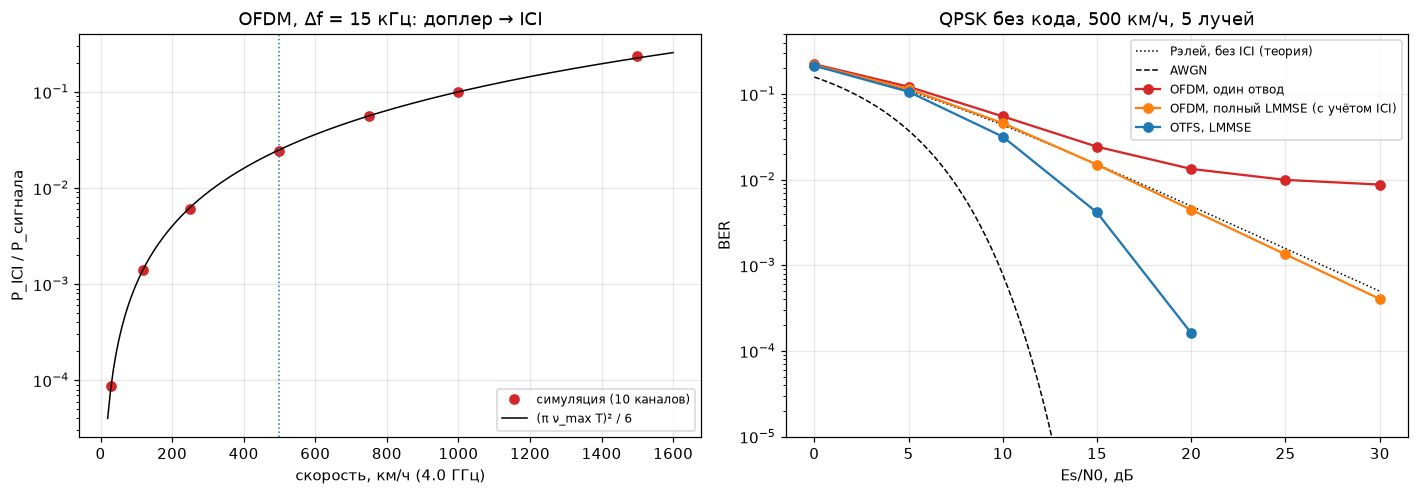

ofdm1 : BER при 20 дБ = 1.3e-02, наклон в конце ≈ 0.1 декады на 10 дБ (порядок разнесения)
ofdm  : BER при 20 дБ = 4.5e-03, наклон в конце ≈ 1.0 декады на 10 дБ (порядок разнесения)
otfs  : BER при 20 дБ = 1.6e-04, наклон в конце ≈ 2.8 декады на 10 дБ (порядок разнесения)


In [6]:
# (а) ICI в OFDM: вся мощность вне диагонали матрицы канала
speeds = np.array([30, 120, 250, 500, 750, 1000, 1500])
sir, sir_th = [], []
for v in speeds:
    nu_max = v / 3.6 * FC_GHZ * 1e9 / 3e8; tot = off = 0; th = []
    for i in range(10):
        r = np.random.default_rng(100 + i)
        p = np.exp(-np.arange(P_PATHS) / 1.5); p /= p.sum()
        nu = nu_max * np.cos(r.uniform(0, 2 * np.pi, P_PATHS))
        pth = [(np.sqrt(pi) * crandn((), r), l, vv) for l, (pi, vv) in enumerate(zip(p, nu))]
        Ho = eff_matrix(pth, ofdm_mod, ofdm_demod)
        d = np.abs(np.diag(Ho))**2; tot += d.sum(); off += (np.abs(Ho)**2).sum() - d.sum()
        th.append(np.sum(p * (1 - np.sinc(nu * T)**2)))
    sir.append(off / tot); sir_th.append(np.mean(th))
print("OFDM, ICI / полезная мощность, дБ: симуляция (точная формула 1 − Σp_i·sinc²(ν_i T))")
print("   " + "  ".join(f"{v} км/ч: {10*np.log10(a):.1f} ({10*np.log10(b):.1f})" for v, a, b in zip(speeds, sir, sir_th)))

# (б) BER: OFDM (один отвод / полный LMMSE) против OTFS (LMMSE)
snrs = np.arange(0, 31, 5)
ber = {k: np.zeros(len(snrs)) for k in ("ofdm1", "ofdm", "otfs")}
t0 = time.time()
for f in range(FRAMES):
    pth = draw_paths(rng)
    Ht, Ho = eff_matrix(pth), eff_matrix(pth, ofdm_mod, ofdm_demod)
    b, x = qpsk_bits(4, rng)
    for i, snr in enumerate(snrs):
        n0 = 10 ** (-snr / 10)
        yo = (Ho @ x.T).T + np.sqrt(n0) * crandn(x.shape, rng)
        ber["ofdm1"][i] += np.mean(hard_bits(yo / np.diag(Ho)) != b)
        ber["ofdm"][i] += np.mean(hard_bits(lmmse(Ho, yo, n0)) != b)
        yt = (Ht @ x.T).T + np.sqrt(n0) * crandn(x.shape, rng)
        ber["otfs"][i] += np.mean(hard_bits(lmmse(Ht, yt, n0)) != b)
ber = {k: v / FRAMES for k, v in ber.items()}
print(f"{FRAMES} реализаций канала за {time.time()-t0:.0f} с")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sv = np.linspace(20, 1600, 200); nuv = sv / 3.6 * FC_GHZ * 1e9 / 3e8
ax[0].semilogy(speeds, sir, "C3o", label="симуляция (10 каналов)")
ax[0].semilogy(sv, (np.pi * nuv * T)**2 / 6, "k-", lw=1, label="(π ν_max T)² / 6")
ax[0].axvline(SPEED_KMH, color="C0", ls=":", lw=1)
ax[0].set_xlabel(f"скорость, км/ч ({FC_GHZ} ГГц)"); ax[0].set_ylabel("P_ICI / P_сигнала"); ax[0].legend(fontsize=8)
ax[0].set_title(f"OFDM, Δf = {DF/1e3:.0f} кГц: доплер → ICI")
g = 10 ** (snrs / 10); sg = np.linspace(0, 30, 100); gg = 10 ** (sg / 10)
ax[1].semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Рэлей, без ICI (теория)")
ax[1].semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
for k, c, lab in (("ofdm1", "C3", "OFDM, один отвод"), ("ofdm", "C1", "OFDM, полный LMMSE (с учётом ICI)"), ("otfs", "C0", "OTFS, LMMSE")):
    ok = ber[k] > 0
    ax[1].semilogy(snrs[ok], ber[k][ok], c + "o-", label=lab)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0, дБ"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title(f"QPSK без кода, {SPEED_KMH} км/ч, {P_PATHS} лучей")
plt.tight_layout(); plt.show()
for k in ber:
    j = np.nonzero(ber[k] > 0)[0][-2:]
    slope = -np.diff(np.log10(ber[k][j]))[0] / (np.diff(snrs[j])[0] / 10) if len(j) == 2 else np.nan
    print(f"{k:6}: BER при 20 дБ = {ber[k][snrs == 20][0]:.1e}, наклон в конце ≈ {slope:.1f} декады на 10 дБ (порядок разнесения)")

## 5. Встроенный пилот: оценка канала прямо в DD
В DD канал неподвижен, поэтому одного пилота на кадр достаточно (Raviteja et al., 2019). Пилот с энергией $|x_p|^2$ ставится в $(l_p,k_p)$, а вокруг — **защитная полоса**: по задержке $\pm l_\max$, по доплеру — на все $N$ бинов (из-за дробного доплера отклик тянется по всей оси). Защита занимает 14 % кадра, и её энергия отдана пилоту (+21.6 дБ). Приёмник смотрит на отклик в защитной полосе, берёт всё, что выше $3\sigma$, как «виртуальные» лучи с **целыми** $(l,k)$ и строит из них $\hat H$.

- **Целый доплер**: лучи попадают точно в клетки, оценка почти идеальна. NMSE падает на 10 дБ за каждые 10 дБ SNR, BER совпадает с точным CSI.
- **Дробный доплер**: каждый луч — это ядро Дирихле. Его хвосты ниже порога теряются, а модель «целые лучи» неточна: межсимвольная утечка с одной позиции не равна утечке с другой (фазы $\phi_i(l,k)$ зависят от $k$). NMSE упирается в −19 дБ, BER — в пол ~$10^{-2}$.

Отсюда интерес к **Zak-OTFS**: там отклик на пилот предсказывает отклик на любой символ точно, в том числе при дробном доплере.

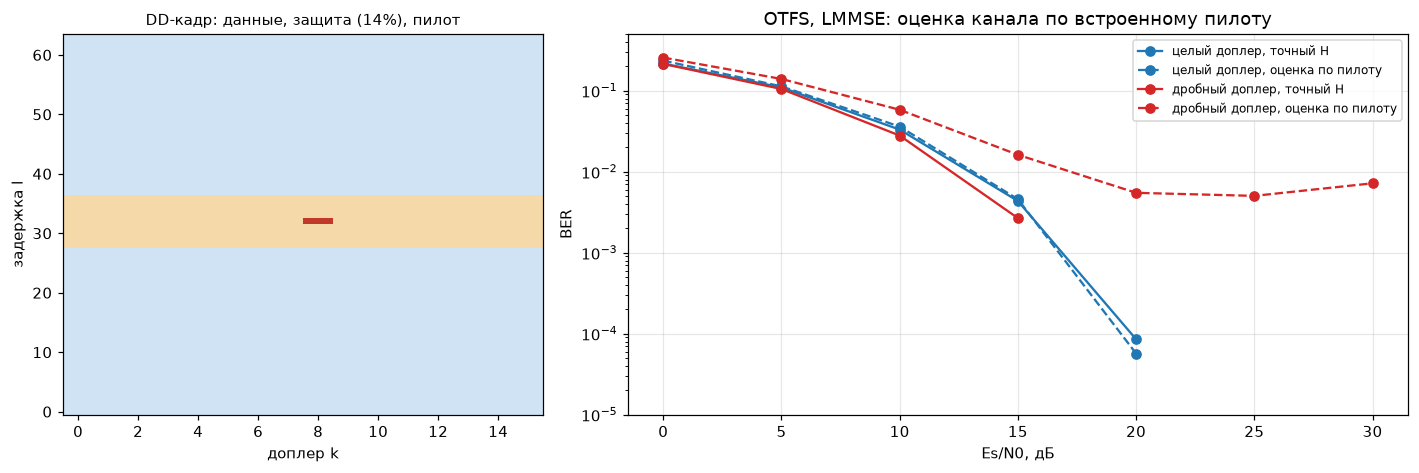

Пилот: 144·Es в одном символе (+21.6 дБ), найдено лучей в среднем 14.4
  SNR  0 дБ: NMSE H целый   -8.7 дБ, дробный   -5.8 дБ
  SNR  5 дБ: NMSE H целый  -15.8 дБ, дробный   -9.0 дБ
  SNR 10 дБ: NMSE H целый  -21.9 дБ, дробный  -11.6 дБ
  SNR 15 дБ: NMSE H целый  -27.5 дБ, дробный  -14.1 дБ
  SNR 20 дБ: NMSE H целый  -32.3 дБ, дробный  -16.4 дБ
  SNR 25 дБ: NMSE H целый  -38.3 дБ, дробный  -17.8 дБ
  SNR 30 дБ: NMSE H целый  -43.2 дБ, дробный  -18.4 дБ


In [7]:
# встроенный пилот (Raviteja et al. 2019): пилот в центре, защитная полоса по задержке, на все доплеры
LP, KP = M // 2, N // 2
GUARD = np.zeros((M, N), bool); GUARD[LP - (P_PATHS - 1):LP + P_PATHS] = True
DATA = ~GUARD.ravel()
XP = np.sqrt(GUARD.sum())                                 # энергия пилота = энергии вытесненных данных

def unit_tap(l, k):
    """матрица одного луча с целыми (l, k) и h = 1"""
    return eff_matrix([(1.0, l, k / (N * T))])

BASIS = {(l, k): unit_tap(l, k) for l in range(P_PATHS) for k in range(-N // 2, N // 2)}

def estimate(y, n0, thr=3.0):
    """DD-отклик на пилот → «виртуальные» целые лучи выше порога thr·σ → оценка H_eff"""
    Y = y.reshape(M, N); He = np.zeros((MN, MN), complex); taps = 0
    for (l, k), Hb in BASIS.items():
        pos = (LP + l) * N + (KP + k) % N
        v = Y.ravel()[pos] / (XP * Hb[pos, LP * N + KP])
        if abs(v) * XP > thr * np.sqrt(n0):
            He += v * Hb; taps += 1
    return He, taps

snrs5 = np.arange(0, 31, 5)
res5 = {k: np.zeros(len(snrs5)) for k in ("int_true", "int_est", "frac_true", "frac_est")}
nmse = {k: np.zeros(len(snrs5)) for k in ("int", "frac")}
ntaps = []
for f in range(FRAMES // 2):
    for integer, tag in ((True, "int"), (False, "frac")):
        pth = draw_paths(rng, integer); H = eff_matrix(pth)
        b, x = qpsk_bits(1, rng)
        x = x * DATA; x[0, LP * N + KP] = XP
        for i, snr in enumerate(snrs5):
            n0 = 10 ** (-snr / 10)
            y = (H @ x[0]) + np.sqrt(n0) * crandn(MN, rng)
            He, nt = estimate(y, n0); ntaps.append(nt)
            nmse[tag][i] += np.sum(np.abs(He - H)**2) / np.sum(np.abs(H)**2)
            for Hd, kk in ((H, "true"), (He, "est")):
                yd = y - Hd[:, LP * N + KP] * XP                  # вычитаем пилот
                z = lmmse(Hd[:, DATA], yd[None], n0)[0]
                res5[f"{tag}_{kk}"][i] += np.mean(hard_bits(z) != b[0, DATA])
res5 = {k: v / (FRAMES // 2) for k, v in res5.items()}; nmse = {k: v / (FRAMES // 2) for k, v in nmse.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [0.8, 1.3]})
G = np.zeros((M, N)); G[GUARD] = 1; G[LP, KP] = 2
ax[0].imshow(G, origin="lower", aspect="auto", cmap=plt.matplotlib.colors.ListedColormap(["#cfe3f5", "#f5d9a8", "#c0392b"]),
             extent=[-0.5, N - 0.5, -0.5, M - 0.5])
ax[0].set_xlabel("доплер k"); ax[0].set_ylabel("задержка l"); ax[0].grid(False)
ax[0].set_title(f"DD-кадр: данные, защита ({GUARD.mean():.0%}), пилот", fontsize=10)
for k, c, ls, lab in (("int_true", "C0", "-", "целый доплер, точный H"), ("int_est", "C0", "--", "целый доплер, оценка по пилоту"),
                      ("frac_true", "C3", "-", "дробный доплер, точный H"), ("frac_est", "C3", "--", "дробный доплер, оценка по пилоту")):
    ok = res5[k] > 0
    ax[1].semilogy(snrs5[ok], res5[k][ok], c + "o", ls=ls, label=lab)
ax[1].set_ylim(1e-5, 0.5); ax[1].set_xlabel("Es/N0, дБ"); ax[1].set_ylabel("BER"); ax[1].legend(fontsize=8)
ax[1].set_title("OTFS, LMMSE: оценка канала по встроенному пилоту")
plt.tight_layout(); plt.show()
print(f"Пилот: {XP**2:.0f}·Es в одном символе (+{10*np.log10(XP**2):.1f} дБ), найдено лучей в среднем {np.mean(ntaps):.1f}")
for i, snr in enumerate(snrs5):
    print(f"  SNR {snr:2d} дБ: NMSE H целый {10*np.log10(nmse['int'][i]):6.1f} дБ, дробный {10*np.log10(nmse['frac'][i]):6.1f} дБ")

## 6. Детектор: передача сообщений вместо обращения матрицы
LMMSE обращает матрицу $MN\times MN$: $O((MN)^3)$, для кадра 64×16 это $10^9$ операций, а для реального 600×14 — уже $6\cdot10^{11}$. Но при целом доплере в каждой строке $H$ всего $P$ ненулевых элементов: граф «наблюдение ↔ символ» разрежен, как у LDPC (`ldpc_sim`). **Передача сообщений с гауссовой аппроксимацией** (Raviteja et al., 2018):
1. наблюдение $y_d$ отправляет символу $c$ среднее и дисперсию помехи от остальных $P-1$ символов строки, $\mu_{d,c}=\sum_{e\ne c}H_{d,e}\,\mathbb E[x_e]$, $\sigma^2_{d,c}=\sum_{e\ne c}|H_{d,e}|^2\mathrm{Var}[x_e]+N_0$;
2. символ собирает от всех своих наблюдений, **кроме** адресата, правдоподобия $\exp(-|y_d-\mu_{d,c}-H_{d,c}a|^2/\sigma^2_{d,c})$ для каждой точки созвездия $a$. Это та же внешняя информация, что в BP и турбокоде;
3. демпфирование $p\leftarrow0.6\,p_\text{new}+0.4\,p_\text{old}$ против колебаний на коротких циклах. Индикатор сходимости — доля символов с апостериорной вероятностью > 0.99.

Сложность $O(MN\cdot P\cdot|\mathcal A|)$ на итерацию. MP при этом **лучше** LMMSE: это нелинейный детектор, который пользуется тем, что символы из конечного алфавита.

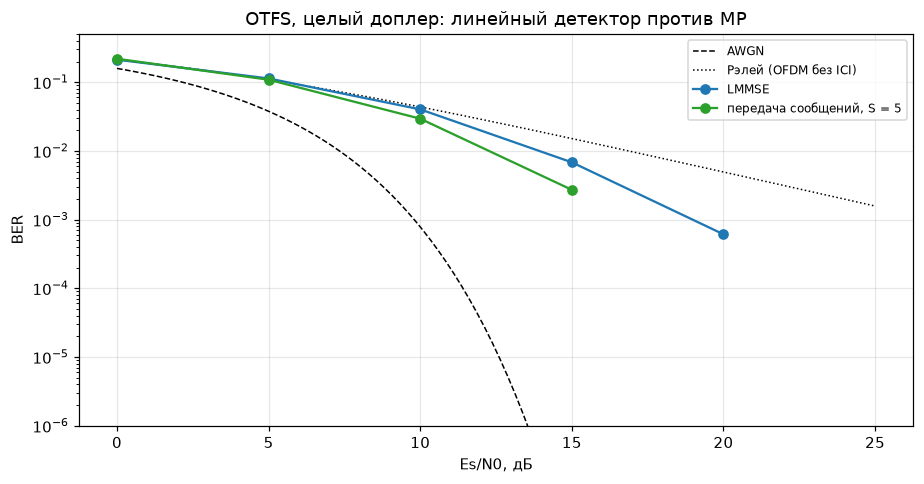

Время на кадр: LMMSE 82 мс (O((MN)³) = 1.1e+09), MP 44 мс (O(MN·S·|A|·итераций) = 6.1e+05)
  SNR  0 дБ: LMMSE 2.1e-01, MP 2.2e-01
  SNR  5 дБ: LMMSE 1.1e-01, MP 1.1e-01
  SNR 10 дБ: LMMSE 4.0e-02, MP 2.9e-02
  SNR 15 дБ: LMMSE 6.8e-03, MP 2.7e-03
  SNR 20 дБ: LMMSE 6.1e-04, MP 0.0e+00
  SNR 25 дБ: LMMSE 0.0e+00, MP 0.0e+00


In [8]:
def mp_detect(y, H, n0, iters=30, damp=0.6, S=None):
    """Передача сообщений с гауссовой аппроксимацией помехи (Raviteja et al. 2018).
    Наблюдение y_d связано только с S сильнейшими символами строки H; помеха от остальных S−1 — гауссова.
    Индикатор сходимости η — доля символов с апостериорной вероятностью > 0.99; берём решение с лучшим η."""
    S = S or int(np.max(np.sum(np.abs(H) > 1e-6 * np.abs(H).max(), 1)))
    idx = np.argsort(-np.abs(H), 1)[:, :S]; h = np.take_along_axis(H, idx, 1)
    A, A2 = QPSK, np.abs(QPSK)**2
    p = np.full((MN, S, 4), 0.25); best, eta_best = None, -1
    for _ in range(iters):
        m = p @ A; v = p @ A2 - np.abs(m)**2
        hm = h * m; hv = np.abs(h)**2 * v
        mu = hm.sum(1, keepdims=True) - hm; s2 = hv.sum(1, keepdims=True) - hv + n0
        ll = -np.abs(y[:, None, None] - mu[..., None] - h[..., None] * A)**2 / s2[..., None]
        LL = np.zeros((MN, 4)); np.add.at(LL, idx.ravel(), ll.reshape(-1, 4))
        post = np.exp(LL - LL.max(1, keepdims=True)); post /= post.sum(1, keepdims=True)
        eta = np.mean(post.max(1) > 0.99)
        if eta > eta_best:
            best, eta_best = A[np.argmax(LL, 1)], eta
        if eta == 1:
            break
        q = LL[idx] - ll; q = np.exp(q - q.max(-1, keepdims=True)); q /= q.sum(-1, keepdims=True)
        p = damp * q + (1 - damp) * p
    return best, S

snrs6 = np.arange(0, 26, 5)
r6 = {k: np.zeros(len(snrs6)) for k in ("lmmse", "mp")}; tl = tm = 0
for f in range(FRAMES // 2):
    pth = draw_paths(rng, integer=True); H = eff_matrix(pth)
    b, x = qpsk_bits(1, rng)
    for i, snr in enumerate(snrs6):
        n0 = 10 ** (-snr / 10); y = H @ x[0] + np.sqrt(n0) * crandn(MN, rng)
        t = time.time(); z = lmmse(H, y[None], n0)[0]; tl += time.time() - t
        t = time.time(); zm, S = mp_detect(y, H, n0); tm += time.time() - t
        r6["lmmse"][i] += np.mean(hard_bits(z) != b[0]); r6["mp"][i] += np.mean(hard_bits(zm) != b[0])
r6 = {k: v / (FRAMES // 2) for k, v in r6.items()}
fig, a = plt.subplots(figsize=(8.5, 4.5))
sg = np.linspace(0, 25, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Рэлей (OFDM без ICI)")
for k, c, lab in (("lmmse", "C0", "LMMSE"), ("mp", "C2", f"передача сообщений, S = {S}")):
    ok = r6[k] > 0
    a.semilogy(snrs6[ok], r6[k][ok], c + "o-", label=lab)
a.set_ylim(1e-6, 0.5); a.set_xlabel("Es/N0, дБ"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"OTFS, целый доплер: линейный детектор против MP")
plt.tight_layout(); plt.show()
print(f"Время на кадр: LMMSE {tl/(len(snrs6)*FRAMES//2)*1e3:.0f} мс (O((MN)³) = {MN**3:.1e}), MP {tm/(len(snrs6)*FRAMES//2)*1e3:.0f} мс (O(MN·S·|A|·итераций) = {MN*S*4*30:.1e})")
for i, snr in enumerate(snrs6):
    print(f"  SNR {snr:2d} дБ: LMMSE {r6['lmmse'][i]:.1e}, MP {r6['mp'][i]:.1e}")

## 7. Пик-фактор
Отсчёт OTFS — сумма $N$ символов (IDFT по доплеру), отсчёт OFDM — сумма $M$. Поэтому без передискретизации пик-фактор кадра OTFS ограничен $10\lg N$ дБ (QPSK, все слагаемые с единичным модулем), а OFDM — $10\lg M$. При малом $N$ OTFS — почти одна несущая. При $N\gtrsim16$ сумма уже гауссова по ЦПТ, и распределение мгновенной мощности совпадает с OFDM ($e^{-z}$). Передискретизация (импульсы между отсчётами) добавляет ~1–3 дБ при малом $N$. Варианты с одной несущей в DD (**OTSM/ODDM**, последний ноутбук серии) используют именно это.

Пик-фактор кадра (без передискретизации); граница — число складываемых символов:
  OFDM:       max 11.3 дБ, граница 10·lg M = 18.1 дБ
  OTFS N =  1: max 0.0 дБ, граница 10·lg N = 0.0 дБ
  OTFS N =  2: max 3.0 дБ, граница 10·lg N = 3.0 дБ
  OTFS N =  4: max 6.0 дБ, граница 10·lg N = 6.0 дБ


  OTFS N = 16: max 10.5 дБ, граница 10·lg N = 12.0 дБ


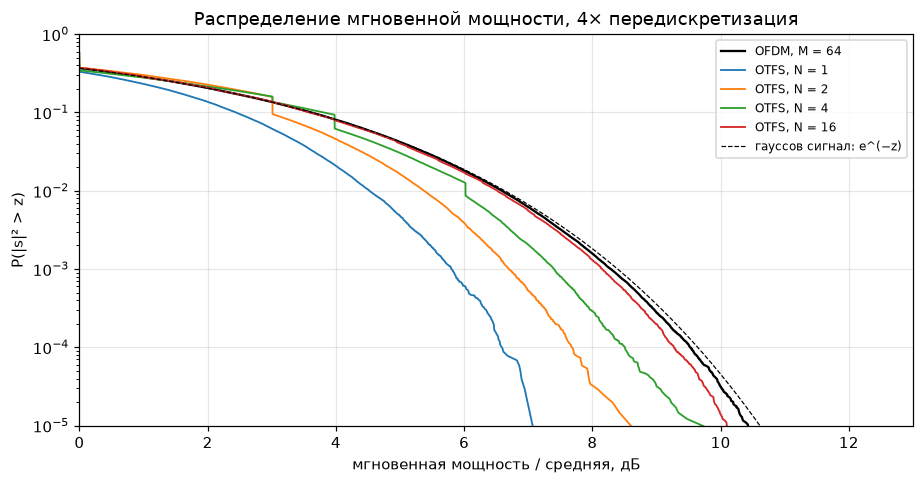

In [9]:
OS, B = 4, 400
def interp(blocks, L):
    """4× передискретизация блока длины L нулями в спектре (идеальный ФНЧ)"""
    F = np.fft.fft(blocks, axis=-1); G = np.zeros(F.shape[:-1] + (L * OS,), complex)
    G[..., :L // 2] = F[..., :L // 2]; G[..., -L // 2:] = F[..., -L // 2:]
    return np.fft.ifft(G, axis=-1) * OS
z = np.linspace(0, 13, 300)
fig, a = plt.subplots(figsize=(8.5, 4.5))
_, X = qpsk_bits(B, rng)
so = interp((np.fft.ifft(X.reshape(B, M, N), axis=1) * np.sqrt(M)).swapaxes(1, 2), M)
pw = np.sort((np.abs(so)**2 / np.mean(np.abs(so)**2)).ravel())
a.semilogy(10 * np.log10(pw + 1e-12), 1 - np.arange(len(pw)) / len(pw), "k", lw=1.5, label=f"OFDM, M = {M}")
print("Пик-фактор кадра (без передискретизации); граница — число складываемых символов:")
print(f"  OFDM:       max {np.max(10*np.log10(np.max(np.abs(np.fft.ifft(X.reshape(B, M, N), axis=1) * np.sqrt(M))**2, axis=(1, 2)))):.1f} дБ, граница 10·lg M = {10*np.log10(M):.1f} дБ")
for i, n_ in enumerate((1, 2, 4, 16)):
    xs = qpsk_bits(B, rng)[1].reshape(B, M, N)[..., :n_]
    blocks = (np.fft.ifft(xs, axis=-1) * np.sqrt(n_)).swapaxes(1, 2)        # (B, n_, M): N блоков по M отсчётов
    st = interp(blocks.reshape(B, -1), M * n_)
    pw = np.sort((np.abs(st)**2 / np.mean(np.abs(st)**2)).ravel())
    a.semilogy(10 * np.log10(pw + 1e-12), 1 - np.arange(len(pw)) / len(pw), f"C{i}", lw=1.2, label=f"OTFS, N = {n_}")
    print(f"  OTFS N = {n_:2d}: max {10*np.log10(np.max(np.abs(blocks)**2)):.1f} дБ, граница 10·lg N = {10*np.log10(n_):.1f} дБ")
a.semilogy(z, np.exp(-10 ** (z / 10)), "k--", lw=0.8, label="гауссов сигнал: e^(−z)")
a.set_ylim(1e-5, 1); a.set_xlim(0, 13); a.set_xlabel("мгновенная мощность / средняя, дБ"); a.set_ylabel("P(|s|² > z)")
a.legend(fontsize=8); a.set_title("Распределение мгновенной мощности, 4× передискретизация")
plt.tight_layout(); plt.show()

## Сравнение с OFDM (LTE)
| | OFDM / LTE | OTFS |
|---|---|---|
| Где живут символы | TF-сетка: поднесущая × символ | DD-сетка: задержка × доплер |
| Канал, который видит символ | одно комплексное число $H[m,n]$, меняется по сетке | 2D-свёртка с несколькими неподвижными лучами |
| Доплер | ICI $\approx(\pi\nu_\max T)^2/6$, пилоты должны успевать за каналом | просто сдвиг по оси доплера, пока $\nu_\max<N/(2\cdot NT)$ |
| Разнесение без кода | 1 (Рэлей на каждом RE) | эффективно ~$P$ (каждый символ на всём кадре) |
| Оценка канала | CRS/DMRS по всей сетке + интерполяция | один пилот + защита (здесь 14 %); дробный доплер — пол |
| Эквалайзер | одно деление на поднесущую | LMMSE $O((MN)^3)$ или MP $O(MN\,P\,|\mathcal A|)$ |
| CP | на каждый символ (здесь 11 %) | один на кадр (0.8 %) |
| Латентность | символ 67 мкс | кадр $NT$ целиком (здесь ~1 мс) |
| PAPR | гауссов, $\sim10\lg M$ граница | $\le10\lg N$: меньше при малом $N$ |
| Совместимость | стандарт 4G/5G | ISFFT-прекодер **поверх** OFDM-модема |

OTFS не отменяет OFDM: это двумерный прекодер (ISFFT) перед тем же модемом. Выигрывает он, когда канал быстро меняется во времени (поезда, самолёты, LEO-спутники, V2X), а код с перемежением не успевает собрать разнесение за отведённую задержку. Когда доплер мал (`SPEED_KMH = 30`), OFDM с хорошим кодом не хуже и гораздо проще. Цена OTFS — сложный детектор и чувствительность к дробному доплеру (раздел 5). Её снижают Zak-OTFS (точная модель канала), AFDM/OCDM (чирп-базис, ещё одна параметризация задержки–доплера) и OTSM/ODDM (одна несущая).

## Что покрутить
- `SPEED_KMH = 30` — в разделе 4 ICI OFDM падает до −40 дБ, одноотводный OFDM совпадает с полным LMMSE и с кривой Рэлея, а OTFS всё равно круче: разнесение по задержкам никуда не делось
- `SPEED_KMH = 1500` — ICI OFDM −6 дБ, а OTFS почти не замечает: $k_\max\approx6$ бинов ещё меньше $N/2$
- `N = 32` (кадр вдвое длиннее) — бин доплера вдвое уже: в разделе 3 больше лучей разрешается отдельно, а в разделе 5 дробный доплер вредит меньше (выше разрешение)
- `P_PATHS = 2` — в разделе 4 наклон OTFS падает примерно до 2: разнесение — это число разрешимых лучей
- `L_CP = 2` при `P_PATHS = 5` — CP короче канала: в OTFS появится межкадровая помеха, в OFDM — межсимвольная (сравните полы)
- в разделе 6 `damp=1.0` (без демпфирования) — у части кадров MP может начать колебаться, тогда появляется пол ошибок